# Six-Supergroup Retrieval Experiment

## Why redefine the retrieval groups?

The first comparison used the original 20 Newsgroups labels as retrieval relevance groups and showed weak results for a single PLSA model. That raised a question about the evaluation itself: do the 20 labels describe document relationships in a way that makes sense for retrieval? Many labels are closely related subtopics—such as different kinds of computer hardware or neighboring political and religious discussions—while a user looking for one broad subject may reasonably consider documents from several labels relevant. Treating every original label as a completely separate target can split related material across many narrow bins. An unsupervised model may represent those related documents together, while a 20-label score counts that as an error.

We therefore proposed a broader, human-defined grouping: combine all 20 source categories into six topical supergroups, then ask whether retrieval looks different when relevance is judged at that broader level. This is an evaluation hypothesis, not a way of teaching PLSA the labels. The model still learns word co-occurrence from document text only; the supergroup labels define the train/test stratification and which held-out documents count as relevant to each query.

We use six groups because they bring together the related source categories while retaining distinct broad areas—computing, technology/engineering, health/space, recreation/consumer exchange, religion/worldview, and politics/international affairs. K=6 is a separate modelling choice tested alongside this grouping: it asks how a six-topic PLSA behaves under six-group evaluation, but does not force a one-to-one topic-to-group mapping. The results will show whether this particular grouping helps the comparison; they cannot establish that these are the only or objectively correct clusters.


## Environment

The next cell contains the optional dependency-install command for notebook environments where these packages are not already available.


In [1]:
# %pip -q install numpy scipy scikit-learn pandas matplotlib


## 1. Libraries and shared settings

The imports cover sparse count matrices and PLSA, TF-IDF and truncated-SVD/LSI baselines, the six-group data split, retrieval scoring, plots, and the topic-alignment diagnostics used later.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.sparse import csr_matrix
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42



## 2. Load the corpus and define the six supergroups

Before fitting any model or inspecting retrieval scores, explicitly map each of the 20 original categories into one of six broad subject families. This grouping is the proposed answer to the evaluation concern above: related subtopics are treated as relevant to the same broad query, while distinct subject areas remain separate.

The output lists each source category and its document count. The corpus is not downsampled to make the six groups equal in size: all 18,846 documents remain available, and the split preserves the natural group proportions. The mapping is checked so every original category appears exactly once. Labels are used to create the evaluation groups, stratify the split, and score retrieval; PLSA's EM fitting uses only word counts.


In [3]:
SUPERGROUPS = {
    "Computing": [
        "comp.graphics",
        "comp.os.ms-windows.misc",
        "comp.sys.ibm.pc.hardware",
        "comp.sys.mac.hardware",
        "comp.windows.x",
    ],
    "Digital technology and engineering": ["sci.crypt", "sci.electronics"],
    "Health and space science": ["sci.med", "sci.space"],
    "Recreation and consumer exchange": [
        "misc.forsale", "rec.autos", "rec.motorcycles",
        "rec.sport.baseball", "rec.sport.hockey"
    ],
    "Religion and worldview": [
        "alt.atheism", "soc.religion.christian", "talk.religion.misc"
    ],
    "Politics and international affairs": [
        "talk.politics.guns", "talk.politics.mideast", "talk.politics.misc"
    ],
}

dataset = fetch_20newsgroups(
    subset="all",
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=SEED
)
documents = np.array(dataset.data, dtype=object)
original_labels = np.asarray(dataset.target)
source_category_names = list(dataset.target_names)

all_mapped_categories = [name for members in SUPERGROUPS.values() for name in members]
missing_categories = sorted(set(source_category_names) - set(all_mapped_categories))
unknown_categories = sorted(set(all_mapped_categories) - set(source_category_names))
duplicate_categories = sorted({name for name in all_mapped_categories if all_mapped_categories.count(name) > 1})
if missing_categories or unknown_categories or duplicate_categories:
    raise ValueError(
        f"Supergroup mapping must cover each source category once. Missing={missing_categories}; "
        f"unknown={unknown_categories}; duplicates={duplicate_categories}"
    )

source_to_supergroup = {
    category: group
    for group, members in SUPERGROUPS.items()
    for category in members
}
target_names = list(SUPERGROUPS)
supergroup_to_id = {name: i for i, name in enumerate(target_names)}
labels = np.asarray([
    supergroup_to_id[source_to_supergroup[source_category_names[label]]]
    for label in original_labels
], dtype=int)

print("Source categories:", len(source_category_names))
print("Evaluation supergroups:", len(target_names))
print("Total documents:", len(documents))
for group_id, group_name in enumerate(target_names):
    member_categories = SUPERGROUPS[group_name]
    count = int((labels == group_id).sum())
    print(f"\n{group_name}: {count} documents")
    for category in member_categories:
        source_id = source_category_names.index(category)
        print(f"  - {category}: {int((original_labels == source_id).sum())} documents")

print("\nAll 20 original categories are assigned exactly once.")
print("Supergroup labels are used for stratification and retrieval evaluation; PLSA fitting remains unsupervised.")


Source categories: 20
Evaluation supergroups: 6
Total documents: 18846

Computing: 4891 documents
  - comp.graphics: 973 documents
  - comp.os.ms-windows.misc: 985 documents
  - comp.sys.ibm.pc.hardware: 982 documents
  - comp.sys.mac.hardware: 963 documents
  - comp.windows.x: 988 documents

Digital technology and engineering: 1975 documents
  - sci.crypt: 991 documents
  - sci.electronics: 984 documents

Health and space science: 1977 documents
  - sci.med: 990 documents
  - sci.space: 987 documents

Recreation and consumer exchange: 4954 documents
  - misc.forsale: 975 documents
  - rec.autos: 990 documents
  - rec.motorcycles: 996 documents
  - rec.sport.baseball: 994 documents
  - rec.sport.hockey: 999 documents

Religion and worldview: 2424 documents
  - alt.atheism: 799 documents
  - soc.religion.christian: 997 documents
  - talk.religion.misc: 628 documents

Politics and international affairs: 2625 documents
  - talk.politics.guns: 910 documents
  - talk.politics.mideast: 940 d

### What the grouping output shows

All 20 source categories were assigned exactly once. The six groups have different natural sizes: Computing and Recreation/consumer exchange are largest, while Digital technology/engineering and Health/space contain two original categories each. These counts describe the corpus and are not forced to equality. Keeping the original documents avoids discarding examples simply to create balanced groups.

This mapping defines the relevance judgments for the experiment. It is a deliberate, interpretable hypothesis about which categories should count as related in retrieval; it is not a clustering discovered by PLSA and is not supplied to the model during training.


## 3. Hold out test documents and build the text representation

Use a stratified 80/20 split over the six supergroups, retaining the full training partition rather than trimming it to the smallest group's size. Fit the vocabulary on training documents only, then transform the held-out test documents with that vocabulary. The same split and preprocessed text feed PLSA and the TF-IDF/LSI comparisons.


In [4]:
import spacy
docs_train, docs_test, y_train, y_test, original_y_train, _ = train_test_split(
    documents,
    labels,
    original_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

print("Training documents per supergroup:", dict(zip(target_names, np.bincount(y_train, minlength=len(target_names)))))
print("Training documents retained:", len(docs_train), "of", len(documents))
print("Held-out test documents retained:", len(docs_test), "of", len(documents))

nlp = spacy.load(
    "en_core_web_sm",
    disable=["ner", "parser"]
)

def preprocess_texts(texts):
    """
    Lowercase, tokenize, remove stop words and punctuation,
    and lemmatize the remaining tokens.

    Returns a list of preprocessed document strings.
    """
    processed_docs = []

    for doc in nlp.pipe(texts, batch_size=256):
        tokens = []

        for token in doc:

            if (
                token.is_space
                or token.is_punct
                or token.like_num
                or not token.is_alpha
            ):
                continue

            if token.is_stop:
                continue

            lemma = token.lemma_.lower().strip()

            if len(lemma) < 2:
                continue

            tokens.append(lemma)

        processed_docs.append(" ".join(tokens))

    return processed_docs

docs_train_processed = preprocess_texts(docs_train)
docs_test_processed = preprocess_texts(docs_test)
nonempty_test_mask = np.asarray([bool(doc.strip()) for doc in docs_test_processed])

count_vectorizer = CountVectorizer(
    lowercase=False,
    tokenizer=str.split,
    token_pattern=None,
    max_features=3000,
    min_df=3,
    max_df=0.90,
    dtype=np.float64
)

X_train = count_vectorizer.fit_transform(
    docs_train_processed
)

X_test = count_vectorizer.transform(
    docs_test_processed
)

vocabulary = count_vectorizer.get_feature_names_out()

print("X_train:", X_train.shape, "(documents, vocabulary)")
print("X_test: ", X_test.shape)
print("Example vocabulary:", vocabulary[:20])

print(
    "Empty training documents after preprocessing:",
    sum(not doc.strip() for doc in docs_train_processed)
)

print(
    "Empty test documents after preprocessing:",
    sum(not doc.strip() for doc in docs_test_processed)
)


Training documents per supergroup: {'Computing': 3913, 'Digital technology and engineering': 1580, 'Health and space science': 1581, 'Recreation and consumer exchange': 3963, 'Religion and worldview': 1939, 'Politics and international affairs': 2100}
Training documents retained: 15076 of 18846
Held-out test documents retained: 3770 of 18846
X_train: (15076, 3000) (documents, vocabulary)
X_test:  (3770, 3000)
Example vocabulary: ['aaron' 'abandon' 'abc' 'abide' 'ability' 'able' 'abortion' 'absolute'
 'absolutely' 'abstract' 'abuse' 'ac' 'academic' 'accelerator' 'accept'
 'acceptable' 'access' 'accident' 'accomplish' 'accord']
Empty training documents after preprocessing: 446
Empty test documents after preprocessing: 121


### Split and preprocessing output

The split contains 15,076 training documents and 3,770 held-out test documents, out of all 18,846 corpus documents. The feature matrices have 3,000 columns, so every method uses the same training-derived vocabulary. Preprocessing leaves 446 training and 121 test documents with no retained terms; these have no usable vector for retrieval, so the later ranking comparison uses the 3,649 non-empty test documents.

## 4. How PLSA represents documents

PLSA models each document as a mixture of latent topics. For a document \(d\), word \(w\), and topic \(z\),

\[P(w\mid d)=\sum_z P(w\mid z)P(z\mid d).\]

The model estimates a topic-word distribution \(P(w\mid z)\) and a document-topic distribution \(P(z\mid d)\) from word counts. During fitting, EM repeatedly assigns observed word counts probabilistically to topics and updates these distributions. The category labels do not enter those updates.


In [5]:
class PLSA:
    """PLSA trained directly with NumPy EM and sparse input counts."""

    def __init__(self, n_topics=5, max_iter=100, tol=1e-4,
                 random_state=42, beta=1.0):
        if n_topics < 1:
            raise ValueError("n_topics must be positive")
        if not (0 < beta):
            raise ValueError("beta must be positive")
        self.n_topics = n_topics
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.beta = beta
        self.log_likelihoods = []

    @staticmethod
    def _normalize(a, axis):
        denom = np.maximum(a.sum(axis=axis, keepdims=True), 1e-15)
        return a / denom

    @staticmethod
    def _observations(X):
        X = csr_matrix(X, dtype=np.float64)
        X.eliminate_zeros()
        X.sum_duplicates()
        docs, words, counts = [], [], []
        for d in range(X.shape[0]):
            start, end = X.indptr[d], X.indptr[d + 1]
            if end > start:
                docs.append(np.full(end-start, d, dtype=np.int64))
                words.append(X.indices[start:end].astype(np.int64))
                counts.append(X.data[start:end].astype(np.float64))
        if not docs:
            raise ValueError("Input has no observed word counts.")
        return X, np.concatenate(docs), np.concatenate(words), np.concatenate(counts)

    def fit(self, X):
        X, doc_ids, word_ids, counts = self._observations(X)
        D, V = X.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state)

        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)
        phi = self._normalize(rng.random((K, V)) + 1e-3, axis=1)
        self.log_likelihoods = []

        for iteration in range(self.max_iter):

            unnorm = theta[doc_ids].T * phi[:, word_ids]
            if self.beta != 1.0:
                unnorm = np.maximum(unnorm, 1e-15) ** self.beta
            posterior = unnorm / np.maximum(
                unnorm.sum(axis=0, keepdims=True), 1e-15
            )

            weighted = posterior * counts[None, :]
            topic_word = np.zeros((K, V), dtype=np.float64)
            doc_topic = np.zeros((D, K), dtype=np.float64)

            for k in range(K):
                np.add.at(topic_word[k], word_ids, weighted[k])
                np.add.at(doc_topic[:, k], doc_ids, weighted[k])

            phi = self._normalize(topic_word + 1e-12, axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)

            p_observed = np.sum(theta[doc_ids] * phi[:, word_ids].T, axis=1)
            ll = float(np.sum(counts * np.log(np.maximum(p_observed, 1e-15))))
            self.log_likelihoods.append(ll)

            if iteration > 0:
                improvement = ll - previous_ll
                if self.beta == 1.0 and improvement < -1e-7:
                    print("Warning: likelihood decreased slightly; check numerical behavior.")
                if abs(improvement) <= self.tol * (1 + abs(previous_ll)):
                    break
            previous_ll = ll

        self.theta_ = theta
        self.phi_ = phi
        self.n_features_in_ = V
        self.n_iter_ = len(self.log_likelihoods)
        return self

    def transform(self):
        """Document-topic probabilities for the documents used in fit()."""
        return self.theta_

    def fold_in(self, X_new, max_iter=100):
        """Infer P(z|d_new) with learned P(w|z) fixed."""
        X_new = csr_matrix(X_new, dtype=np.float64)
        if X_new.shape[1] != self.n_features_in_:
            raise ValueError("New data must use the same fitted vocabulary.")
        D, V = X_new.shape
        K = self.n_topics
        rng = np.random.default_rng(self.random_state + 1000)
        theta = self._normalize(rng.random((D, K)) + 1e-3, axis=1)

        for _ in range(max_iter):
            doc_topic = np.zeros((D, K), dtype=np.float64)
            for d in range(D):
                start, end = X_new.indptr[d], X_new.indptr[d + 1]
                words = X_new.indices[start:end]
                counts = X_new.data[start:end]
                if len(words) == 0:
                    continue
                unnorm = theta[d, :, None] * self.phi_[:, words]
                if self.beta != 1.0:
                    unnorm = np.maximum(unnorm, 1e-15) ** self.beta
                posterior = unnorm / np.maximum(
                    unnorm.sum(axis=0, keepdims=True), 1e-15
                )
                doc_topic[d] = (posterior * counts[None, :]).sum(axis=1)
            theta = self._normalize(doc_topic + 1e-12, axis=1)
        return theta

    def top_words(self, vocabulary, n=10):
        result = {}
        for k, dist in enumerate(self.phi_):
            ids = np.argsort(dist)[::-1][:n]
            result[k] = [(vocabulary[i], float(dist[i])) for i in ids]
        return result


## 5. Fit the primary PLSA model

The primary PLSA uses K=6 to examine whether six latent topics work well under the six-supergroup relevance definition. The labels do not pin topics to groups. EM can settle at different local optima, so five initializations are fitted on the entire 80% training partition. The selected model is the run with the highest training log-likelihood; held-out retrieval scores are not used to select it. The settings match the baseline family: up to 100 iterations, tolerance 1e-4, beta=1.0, and consecutive seeds beginning at 42.


In [6]:
def train_plsa_restarts(X, n_topics=6, n_restarts=5,
                        max_iter=100, tol=1e-4, base_seed=42):
    runs = []
    for r in range(n_restarts):
        model = PLSA(
            n_topics=n_topics, max_iter=max_iter, tol=tol,
            random_state=base_seed + r, beta=1.0
        ).fit(X)
        final_ll = model.log_likelihoods[-1]
        runs.append((model, final_ll))
        print(f"Restart {r+1}: final training log-likelihood={final_ll:.3f}, "
              f"iterations={model.n_iter_}")
    best_model, best_ll = max(runs, key=lambda item: item[1])
    print("Selected best training likelihood:", round(best_ll, 3))
    return best_model, runs

K = 6
best_plsa, restart_runs = train_plsa_restarts(
    X_train, n_topics=K, n_restarts=5, max_iter=100
)
theta_train = best_plsa.transform()
theta_test = best_plsa.fold_in(X_test, max_iter=100)
print("theta_train:", theta_train.shape)
print("theta_test:", theta_test.shape)


Restart 1: final training log-likelihood=-6273009.364, iterations=44
Restart 2: final training log-likelihood=-6277750.970, iterations=40
Restart 3: final training log-likelihood=-6275103.752, iterations=46
Restart 4: final training log-likelihood=-6277416.226, iterations=51
Restart 5: final training log-likelihood=-6275063.638, iterations=42
Selected best training likelihood: -6273009.364
theta_train: (15076, 6)
theta_test: (3770, 6)


### PLSA fitting output

The five initializations converged in 40–51 iterations. The run with the highest training log-likelihood (−6,273,009.364) was selected, and the model produced six topic weights for each training and test document. This selection criterion chooses a fit to the training word counts; it does not guarantee the best retrieval ranking.

## 6. Inspect the learned topics and their relation to groups

The next output lists the highest-probability words for each topic and plots training log-likelihood over EM iterations. Topic numbers are arbitrary; interpret a topic from its word distribution rather than its ID. Held-out NMI and ARI compare each test document's dominant topic with its supergroup. They summarize alignment after fitting and do not make PLSA supervised.



Topic 0:
year (0.008), say (0.006), people (0.006), new (0.006), president (0.006), go (0.005), state (0.005), government (0.005), report (0.005), national (0.005), university (0.005), think (0.005)

Topic 1:
file (0.021), program (0.012), image (0.011), use (0.010), available (0.008), version (0.008), include (0.007), window (0.007), mail (0.007), information (0.007), send (0.007), software (0.006)

Topic 2:
like (0.014), know (0.012), car (0.010), good (0.010), get (0.010), look (0.008), buy (0.008), want (0.008), thank (0.008), go (0.008), gun (0.008), think (0.007)

Topic 3:
drive (0.018), system (0.017), key (0.015), use (0.014), problem (0.011), chip (0.009), bit (0.009), work (0.009), disk (0.009), know (0.008), hard (0.007), need (0.007)

Topic 4:
people (0.014), god (0.011), think (0.009), say (0.008), know (0.008), believe (0.007), right (0.006), like (0.005), come (0.005), thing (0.005), way (0.005), mean (0.005)

Topic 5:
game (0.017), year (0.012), team (0.010), play (0.0

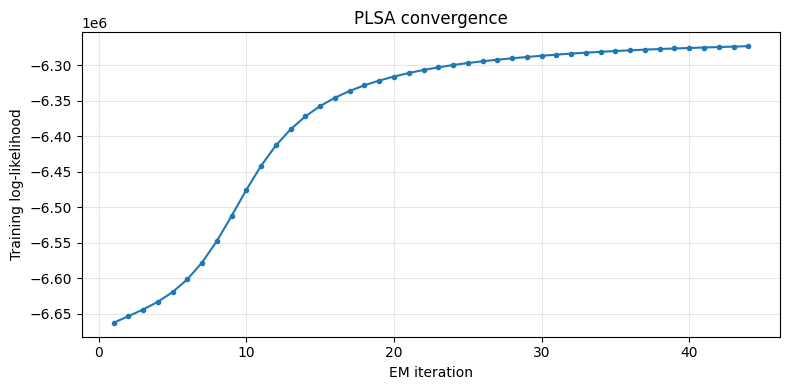

Held-out topic/group NMI: 0.306
Held-out topic/group ARI: 0.231


In [7]:
for topic_id, words in best_plsa.top_words(vocabulary, n=12).items():
    print(f"\nTopic {topic_id}:")
    print(", ".join(f"{word} ({prob:.3f})" for word, prob in words))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(best_plsa.log_likelihoods)+1),
         best_plsa.log_likelihoods, marker="o", markersize=3)
plt.xlabel("EM iteration")
plt.ylabel("Training log-likelihood")
plt.title("PLSA convergence")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


test_topic_assignments = np.argmax(theta_test[nonempty_test_mask], axis=1)
test_group_labels = y_test[nonempty_test_mask]
print("Held-out topic/group NMI:", round(normalized_mutual_info_score(test_group_labels, test_topic_assignments), 3))
print("Held-out topic/group ARI:", round(adjusted_rand_score(test_group_labels, test_topic_assignments), 3))


### Topic inspection and alignment results

The top words show interpretable structure, but not a clean six-way reproduction of the supergroups. One topic is dominated by software and files, another by drives and hardware terms, and others emphasize religion/worldview, games/sports, or broad political and conversational vocabulary. Several topics contain generic words or mix subject areas, which is consistent with PLSA learning word co-occurrence rather than the declared taxonomy.

The held-out dominant-topic alignment is NMI=0.306 and ARI=0.231. These values indicate partial correspondence, not a one-topic-per-supergroup match. The convergence plot shows the selected model's training likelihood improving until its stopping point; likelihood is a fit diagnostic, not a retrieval metric.

## 7. Controlled topic-boundary probe

To inspect how topic weights respond to mixed content, generate artificial documents from baseball and gun-politics training documents using known token proportions. Identify the topic most associated with each source category from training-document topic averages, infer topic proportions for the mixtures, and summarize 20 sampled mixtures at each proportion. This is a controlled diagnostic of the learned representation, separate from the retrieval benchmark.


In [8]:
sports_class = source_category_names.index("rec.sport.baseball")
politics_class = source_category_names.index("talk.politics.guns")

source_category_topic_means = np.vstack([
    theta_train[original_y_train == c].mean(axis=0)
    for c in range(len(source_category_names))
])
sports_topic = int(source_category_topic_means[sports_class].argmax())
politics_topic = int(source_category_topic_means[politics_class].argmax())

print("Sports-associated topic:", sports_topic)
print("Politics-associated topic:", politics_topic)
if sports_topic == politics_topic:
    print("Warning: both source categories map to the same dominant topic; interpret estimates cautiously.")

def sample_token_ids(row):
    row = csr_matrix(row)
    return np.repeat(row.indices, row.data.astype(int))

def make_mixed_document(X_source, source_labels, class_a, class_b,
                        ratio_a, rng, n_tokens=300):

    a_candidates = np.where((source_labels == class_a) & (np.asarray(X_source.sum(axis=1)).ravel() > 0))[0]
    b_candidates = np.where((source_labels == class_b) & (np.asarray(X_source.sum(axis=1)).ravel() > 0))[0]

    da = X_source[a_candidates[rng.integers(len(a_candidates))]]
    db = X_source[b_candidates[rng.integers(len(b_candidates))]]
    tokens_a = sample_token_ids(da)
    tokens_b = sample_token_ids(db)
    if len(tokens_a) == 0 or len(tokens_b) == 0:
        raise ValueError("A sampled source document had no in-vocabulary tokens.")
    n_a = int(round(n_tokens * ratio_a))
    n_b = n_tokens - n_a
    tokens = np.concatenate([
        rng.choice(tokens_a, size=n_a, replace=True),
        rng.choice(tokens_b, size=n_b, replace=True)
    ])
    counts = np.bincount(tokens, minlength=X_source.shape[1]).astype(float)
    return csr_matrix(counts.reshape(1, -1))

boundary_rng = np.random.default_rng(SEED + 77)
ratios = [0.9, 0.7, 0.5, 0.3, 0.1]
boundary_rows = []

for ratio in ratios:
    for replicate in range(20):
        mixed_X = make_mixed_document(
            X_train, original_y_train, sports_class, politics_class,
            ratio, boundary_rng, n_tokens=300
        )
        estimate = best_plsa.fold_in(mixed_X, max_iter=100)[0]
        boundary_rows.append({
            "source_category_a": "rec.sport.baseball",
            "source_category_b": "talk.politics.guns",
            "actual_sports_word_ratio": ratio,
            "actual_politics_word_ratio": 1-ratio,
            "estimated_sports_topic": estimate[sports_topic],
            "estimated_politics_topic": estimate[politics_topic],
            "replicate": replicate
        })

boundary_df = pd.DataFrame(boundary_rows)
boundary_summary = boundary_df.groupby("actual_sports_word_ratio").agg(
    estimated_sports_mean=("estimated_sports_topic", "mean"),
    estimated_sports_std=("estimated_sports_topic", "std"),
    estimated_politics_mean=("estimated_politics_topic", "mean"),
    estimated_politics_std=("estimated_politics_topic", "std")
).reset_index()
display(boundary_summary)


Sports-associated topic: 5
Politics-associated topic: 4


,actual_sports_word_ratio,estimated_sports_mean,estimated_sports_std,estimated_politics_mean,estimated_politics_std
0,0.1,0.078921,0.071421,0.399580,0.279065
1,0.3,0.201470,0.158579,0.374778,0.281066
2,0.5,0.388422,0.151784,0.246022,0.180082
3,0.7,0.488366,0.234252,0.196340,0.138780
4,0.9,0.681589,0.277624,0.079115,0.085779


### Mixture table results

The estimated mean baseball-associated topic weight rises from 0.079 when the generated documents contain 10% baseball tokens to 0.682 at 90%. The increase is directionally consistent with the known mixture ratio, but it is not a one-to-one estimate: the model underestimates the higher baseball proportions, and the standard deviations show variation among sampled documents. Topic probabilities reflect the model's learned latent representation, not a direct count of source words.

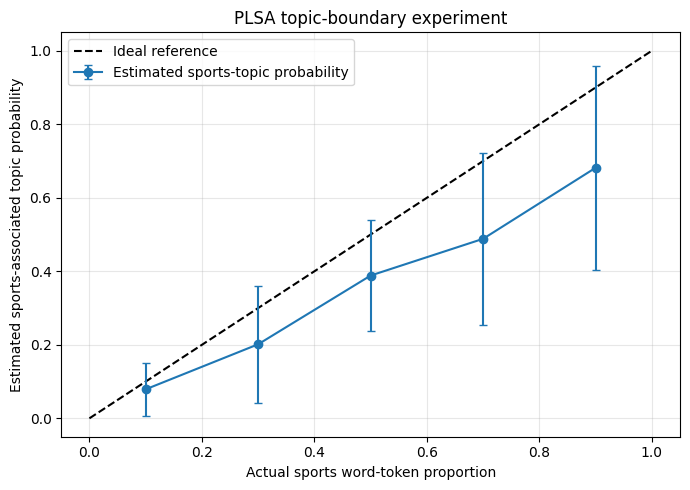

In [9]:
plt.figure(figsize=(7, 5))
plt.plot([0, 1], [0, 1], "k--", label="Ideal reference")
plt.errorbar(
    boundary_summary["actual_sports_word_ratio"],
    boundary_summary["estimated_sports_mean"],
    yerr=boundary_summary["estimated_sports_std"],
    marker="o", capsize=3, label="Estimated sports-topic probability"
)
plt.xlabel("Actual sports word-token proportion")
plt.ylabel("Estimated sports-associated topic probability")
plt.title("PLSA topic-boundary experiment")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 8. TF-IDF, LSI, and category-structure diagnostic

Fit the retrieval baselines using the same full training split and training-only vocabulary used by PLSA. As a check on the proposed supergroups, compare TF-IDF centroids for the original categories: report average within-supergroup category similarity and similarity to categories outside the group. This diagnostic does not define or optimize the groups and does not use test data; it helps reveal whether the proposed grouping is internally coherent in the training text.

In [10]:
tfidf_vectorizer = TfidfVectorizer(
    lowercase=False,
    tokenizer=str.split,
    token_pattern=None,
    max_features=3000,
    min_df=3,
    max_df=0.90
)

X_train_tfidf = tfidf_vectorizer.fit_transform(docs_train_processed)
X_test_tfidf = tfidf_vectorizer.transform(docs_test_processed)

n_components = min(50, X_train_tfidf.shape[0]-1, X_train_tfidf.shape[1]-1)
lsi_model = make_pipeline(
    TruncatedSVD(n_components=n_components, random_state=SEED),
    Normalizer(copy=False)
)
lsi_train = lsi_model.fit_transform(X_train_tfidf)
lsi_test = lsi_model.transform(X_test_tfidf)

print("TF-IDF train/test:", X_train_tfidf.shape, X_test_tfidf.shape)
print("LSI train/test:", lsi_train.shape, lsi_test.shape)


category_centroids = np.vstack([
    np.asarray(X_train_tfidf[original_y_train == category_id].mean(axis=0)).ravel()
    for category_id in range(len(source_category_names))
])
category_centroid_similarity = cosine_similarity(category_centroids)
source_to_group = source_to_supergroup
similarity_rows = []
for group_name, members in SUPERGROUPS.items():
    member_ids = [source_category_names.index(name) for name in members]
    other_ids = [i for i, name in enumerate(source_category_names) if source_to_group[name] != group_name]
    within_values = [
        category_centroid_similarity[i, j]
        for pos, i in enumerate(member_ids)
        for j in member_ids[pos + 1:]
    ]
    between_values = [category_centroid_similarity[i, j] for i in member_ids for j in other_ids]
    similarity_rows.append({
        "supergroup": group_name,
        "source_categories": len(member_ids),
        "mean_within_group_category_cosine": float(np.mean(within_values)) if within_values else np.nan,
        "mean_to_other_group_category_cosine": float(np.mean(between_values)) if between_values else np.nan,
        "closest_external_category": source_category_names[other_ids[int(np.argmax([category_centroid_similarity[member_ids].mean(axis=0)[i] for i in other_ids]))]]
    })
print("Category-centroid similarity check (training data only):")
display(pd.DataFrame(similarity_rows))


TF-IDF train/test: (15076, 3000) (3770, 3000)
LSI train/test: (15076, 50) (3770, 50)
Category-centroid similarity check (training data only):


,supergroup,source_categories,mean_within_group_category_cosine,mean_to_other_group_category_cosine,closest_external_category
0,Computing,5,0.608525,0.354760,sci.electronics
1,Digital technology and engineering,2,0.525299,0.431058,comp.graphics
2,Health and space science,2,0.485508,0.422748,talk.politics.misc
3,Recreation and consumer exchange,5,0.401558,0.354702,sci.electronics
4,Religion and worldview,3,0.818405,0.390659,talk.politics.misc
5,Politics and international affairs,3,0.621263,0.401345,talk.religion.misc


### Baseline and group-structure output

The TF-IDF matrix uses the shared 3,000-term feature limit, and LSI represents documents in 50 dimensions. The centroid table shows that the proposed supergroups are not equally compact: for example, the religion/worldview categories have relatively high within-group similarity, while recreation/consumer exchange is less cohesive. Some groups are also close to categories assigned elsewhere. This supports treating the six-group mapping as a reasoned working taxonomy rather than assuming it forms six perfectly separated clusters.

## 9. Retrieval evaluation

Each supergroup has one fixed broad query. A held-out document is relevant when its original category belongs to the query's supergroup. All methods rank the same non-empty test candidates. The per-query table shows the six query results; the macro table gives each query equal weight.

Precision@10 and Recall@10 count relevant documents in the top ten. AP@10 averages precision at relevant ranks through rank 10, normalized by the smaller of ten and the number of relevant test documents; MAP@10 averages AP@10 over queries. NDCG@10 uses binary supergroup relevance and accounts for ranking positions. Labels supply proxy relevance judgments.


In [11]:
supergroup_queries = {
    "Computing": "computer graphics software hardware operating systems windows",
    "Digital technology and engineering": "electronics circuits encryption cryptography hardware",
    "Health and space science": "medicine health disease doctor space NASA planet",
    "Recreation and consumer exchange": "cars motorcycles baseball hockey sports sale price",
    "Religion and worldview": "religion atheist christian belief faith god",
    "Politics and international affairs": "politics government guns international middle east policy",
}

missing = sorted(set(target_names) - set(supergroup_queries))
extra = sorted(set(supergroup_queries) - set(target_names))
print("Supergroups without a query:", missing)
print("Query names not found in supergroups:", extra)
if missing or extra:
    raise ValueError("Provide exactly one query for each evaluation supergroup.")

print("Non-empty test documents:", int(nonempty_test_mask.sum()), "/", len(docs_test_processed))

def evaluate_query(query_text, target_label, k=10):
    processed_query = preprocess_texts([query_text])[0]
    if not processed_query.strip():
        print(f"Warning: query for {target_names[target_label]} became empty after preprocessing.")

    q_tfidf = tfidf_vectorizer.transform([processed_query])
    q_lsi = lsi_model.transform(q_tfidf)
    q_counts = count_vectorizer.transform([processed_query]).astype(np.float64)
    q_plsa = best_plsa.fold_in(q_counts, max_iter=100)

    sim_tfidf = cosine_similarity(q_tfidf, X_test_tfidf).ravel()[nonempty_test_mask]
    sim_lsi = cosine_similarity(q_lsi, lsi_test).ravel()[nonempty_test_mask]
    sim_plsa = cosine_similarity(q_plsa, theta_test).ravel()[nonempty_test_mask]

    y_eval = y_test[nonempty_test_mask]
    methods = {
        "TF-IDF/VSM": sim_tfidf,
        "LSI": sim_lsi,
        "PLSA": sim_plsa,
    }
    rows = []
    total_relevant = int((y_eval == target_label).sum())
    if total_relevant == 0:
        return rows

    for method_name, scores in methods.items():
        ranked_indices = np.argsort(scores)[::-1]
        top_count = min(k, len(ranked_indices))
        top_relevance = (y_eval[ranked_indices[:top_count]] == target_label).astype(float)
        relevant_retrieved = int(top_relevance.sum())
        precision = relevant_retrieved / top_count if top_count else 0.0
        recall = relevant_retrieved / total_relevant
        precision_at_ranks = np.cumsum(top_relevance) / np.arange(1, top_count + 1)
        ap_at_k = float(np.sum(precision_at_ranks * top_relevance) / min(total_relevant, top_count)) if top_count else 0.0
        discounts = 1.0 / np.log2(np.arange(2, top_count + 2))
        dcg_at_k = float(np.sum(top_relevance * discounts))
        ideal_relevant_count = min(total_relevant, top_count)
        ideal_dcg_at_k = float(np.sum(1.0 / np.log2(np.arange(2, ideal_relevant_count + 2))))
        ndcg_at_k = dcg_at_k / ideal_dcg_at_k if ideal_dcg_at_k else 0.0
        rows.append({
            "query_supergroup": target_names[target_label],
            "query_text": query_text,
            "method": method_name,
            "Precision@10": precision,
            "Recall@10": recall,
            "MAP@10": ap_at_k,
            "NDCG@10": ndcg_at_k,
            "relevant_test_documents": total_relevant,
        })
    return rows

eval_rows = []
for category_name in target_names:
    eval_rows.extend(evaluate_query(supergroup_queries[category_name], target_names.index(category_name), k=10))

evaluation_df = pd.DataFrame(eval_rows)
metric_columns = ["Precision@10", "Recall@10", "MAP@10", "NDCG@10"]
print("Per-query results:")
display(evaluation_df[["query_supergroup", "method", *metric_columns, "relevant_test_documents"]].round(4))

mean_metrics = (
    evaluation_df.groupby("method", sort=False)[metric_columns]
    .mean()
    .reset_index()
    .rename(columns={"method": "Method"})
)
print("Macro-average across the six queries:")
display(mean_metrics.round(4))


Supergroups without a query: []
Query names not found in supergroups: []
Non-empty test documents: 3649 / 3770
Per-query results:


,query_supergroup,method,Precision@10,Recall@10,MAP@10,NDCG@10,relevant_test_documents
0,Computing,TF-IDF/VSM,0.9,0.0095,0.8521,0.9216,950
1,Computing,LSI,0.7,0.0074,0.5000,0.6403,950
2,Computing,PLSA,0.8,0.0084,0.7532,0.8553,950
3,Digital technology and engineering,TF-IDF/VSM,0.9,0.0234,0.8354,0.9149,385
4,Digital technology and engineering,LSI,1.0,0.0260,1.0000,1.0000,385
5,Digital technology and engineering,PLSA,0.0,0.0000,0.0000,0.0000,385
6,Health and space science,TF-IDF/VSM,0.9,0.0236,0.8521,0.9216,381
7,Health and space science,LSI,1.0,0.0262,1.0000,1.0000,381
8,Health and space science,PLSA,0.4,0.0105,0.2711,0.4815,381
9,Recreation and consumer exchange,TF-IDF/VSM,1.0,0.0105,1.0000,1.0000,949


Macro-average across the six queries:


,Method,Precision@10,Recall@10,MAP@10,NDCG@10
0,TF-IDF/VSM,0.8833,0.0166,0.8189,0.8982
1,LSI,0.8333,0.0167,0.7155,0.8077
2,PLSA,0.4333,0.0068,0.2858,0.4248


### Retrieval results: single best-restart models

The six-query macro table shows that the broader relevance groups alone do not make a single PLSA model competitive in this run. TF-IDF/VSM leads with Precision@10=0.8833, MAP@10=0.8189, and NDCG@10=0.8982. LSI is next on those measures, with 0.8333, 0.7155, and 0.8077. The best-restart PLSA model scores 0.4333, 0.2858, and 0.4248, respectively. Recall@10 is low for all three because each query has hundreds of relevant test documents while only ten are retrieved.

The per-query table adds an important detail: no method wins every group. TF-IDF is strong for Computing and Recreation/consumer exchange, while LSI reaches perfect top-ten precision and MAP for Digital technology/engineering and Health/space. PLSA's best-restart scores vary considerably across groups and are especially weak for Digital technology/engineering and Politics/international affairs. The plots show these four metrics separately so each scale remains readable; use the tables for exact comparisons.


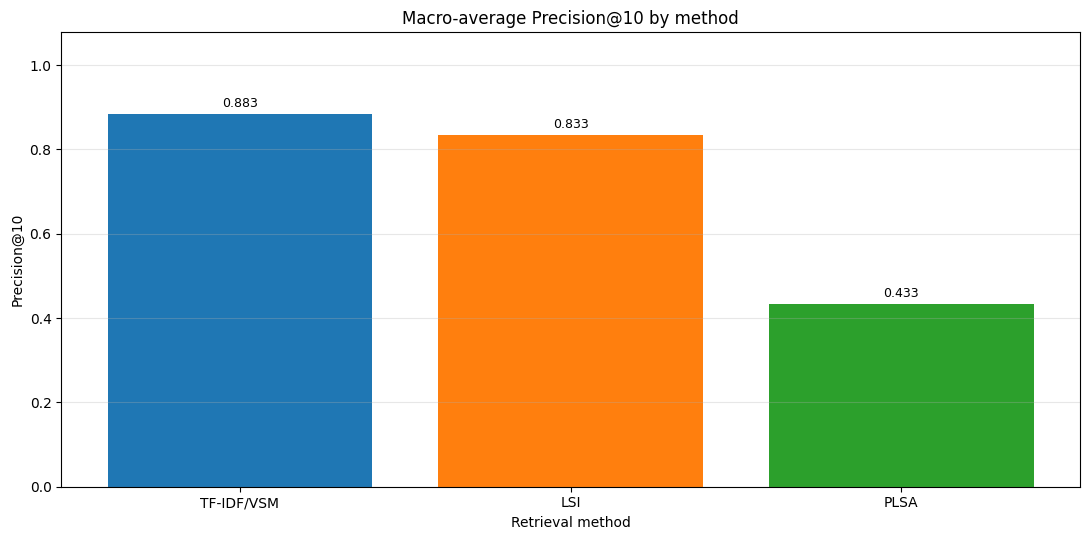

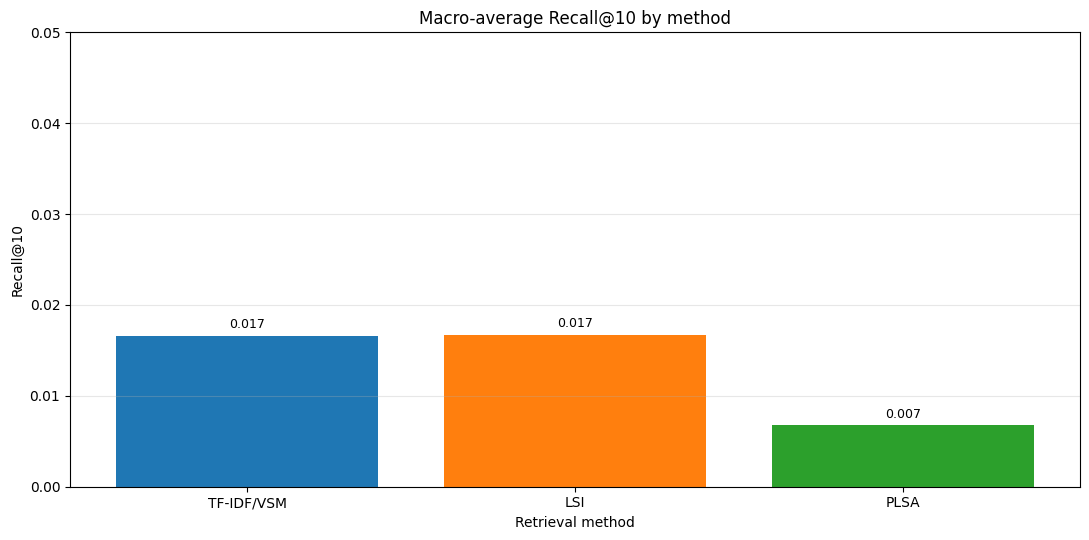

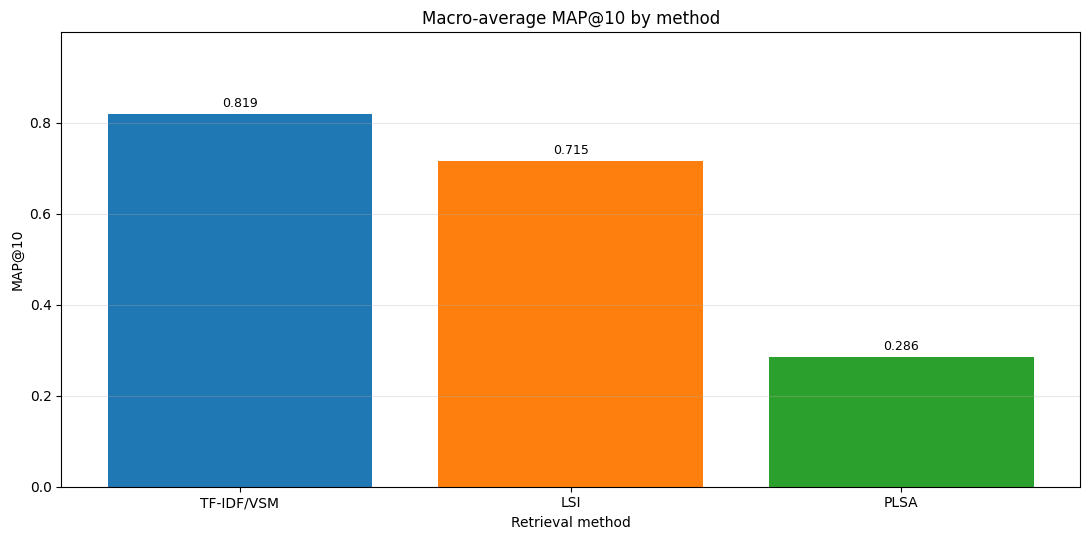

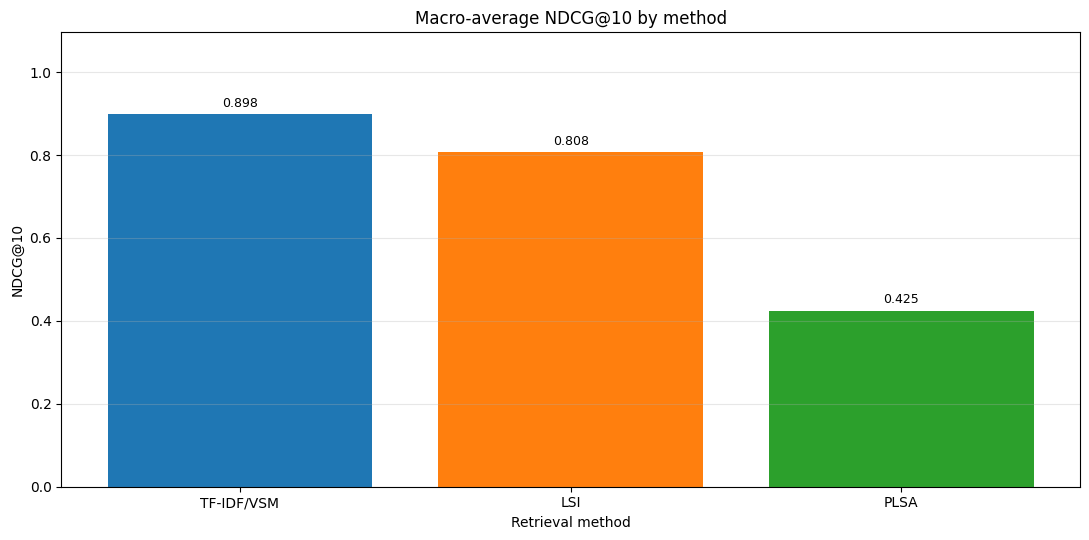

In [12]:
metric_columns = ["Precision@10", "Recall@10", "MAP@10", "NDCG@10"]
method_colors = dict(zip(mean_metrics["Method"], plt.cm.tab10.colors))
method_labels = {
    "TF-IDF/VSM": "TF-IDF/VSM",
    "LSI": "LSI",
    "PLSA": "PLSA",
}

for metric in metric_columns:
    values = mean_metrics[metric].to_numpy(dtype=float)
    upper_limit = min(1.15, max(0.05, float(values.max()) * 1.22))
    plot_labels = [method_labels[method] for method in mean_metrics["Method"]]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    bars = ax.bar(
        plot_labels,
        values,
        color=[method_colors[method] for method in mean_metrics["Method"]]
    )
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.set_ylim(0, upper_limit)
    ax.set_title(f"Macro-average {metric} by method")
    ax.set_ylabel(metric)
    ax.set_xlabel("Retrieval method")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()


### Retrieval plot interpretation

The four charts visualize the macro-average values in the table immediately above. TF-IDF/VSM has the strongest overall single-model scores in this run, with LSI performing well on some individual groups. The PLSA best-restart bars are lower on all four macro metrics. The separate plots make Recall@10 visible without compressing the other measures; the tabular values remain the precise comparison.

## 10. Explore topic count and held-out alignment

The final diagnostic fits one PLSA initialization at each K in 2, 5, 6, 8, 10, and 20, using the same full training matrix. It reports training likelihood and compares dominant held-out topics with the six evaluation groups using NMI and ARI. Because each K uses one initialization and alignment is not retrieval, treat this table as a diagnostic alongside—not a replacement for—the retrieval results above.

In [13]:
k_rows = []
for k_topics in [2, 5, 6, 8, 10, 20]:
    model = PLSA(
        n_topics=k_topics, max_iter=80, tol=1e-4,
        random_state=SEED, beta=1.0
    ).fit(X_train)
    theta_candidate = model.fold_in(X_test, max_iter=100)
    candidate_topics = np.argmax(theta_candidate[nonempty_test_mask], axis=1)
    heldout_groups = y_test[nonempty_test_mask]
    k_rows.append({
        "K": k_topics,
        "iterations": model.n_iter_,
        "train_log_likelihood": model.log_likelihoods[-1],
        "heldout_NMI": normalized_mutual_info_score(heldout_groups, candidate_topics),
        "heldout_ARI": adjusted_rand_score(heldout_groups, candidate_topics),
        "test_documents": X_test.shape[0]
    })

k_df = pd.DataFrame(k_rows)
display(k_df)


,K,iterations,train_log_likelihood,heldout_NMI,heldout_ARI,test_documents
0,2,47,-6.524626e+06,0.201722,0.187904,3770
1,5,39,-6.298452e+06,0.325251,0.253428,3770
2,6,44,-6.273009e+06,0.306179,0.230618,3770
3,8,46,-6.194436e+06,0.363117,0.343314,3770
4,10,57,-6.132728e+06,0.321850,0.221803,3770
5,20,55,-5.980703e+06,0.323127,0.189936,3770


### What the K sweep shows

K=8 gives the strongest held-out alignment in this saved sweep (NMI=0.363; ARI=0.343). K=6 is lower (0.306; 0.231), and K=20 does not improve both measures despite its higher training likelihood. The alignment table therefore does not support setting K equal to the number of relevance groups as a general rule; it also does not rank retrieval quality.
